# Week 5: length-scale cap sensitivity

Reproduce **Maximized log marginal likelihood vs maximum length-scale bound** from [Week 1 notebook 02](../week_1/02_all_functions_length_scale_sensitivity.ipynb), using observations **through week 5** and the five current package kernels. Sweep caps from `0.01` to `1,000`, including each function's configured cap. Dashed lines mark those configured values; this notebook does not select or change them.

Each fit starts fresh with the same configured seed, target normalization, and optimizer restarts. The length-scale lower bound stays at `1e-3`; for caps below `1`, initialize the length scale at the cap so it remains feasible. The length-cap sweep now uses a **WhiteKernel noise-variance lower bound of `1e-12`**. At the configured length caps, compare noise floors `1e-8`, `1e-10`, and `1e-12` for all functions and all five kernels. Only this notebook overrides the noise bound; shared kernel defaults stay unchanged.

Other parameters use the shared kernel factory's settings (including its periodic-kernel initialization), rather than duplicating the historical constructors. This is an in-sample fit diagnostic, not held-out validation. No candidates or data exports are written.

In [1]:
%matplotlib inline
from pathlib import Path
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.data import load_observations
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.surrogate import fit_surrogate

WEEK = 5
FUNCTION_IDS = tuple(FUNCTION_SPECS)
CONFIGURED_CAPS = CONFIG['length_caps']
CAP_VALUES = np.logspace(-2, 3, 11)
NOISE_FLOORS = (1e-8, 1e-10, 1e-12)
SWEEP_NOISE_FLOOR = NOISE_FLOORS[-1]
data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
observations_by_function = {
    function_id: load_observations(data_root, function_id, up_to_week=WEEK)
    for function_id in FUNCTION_IDS
}
plt.style.use('seaborn-v0_8-whitegrid')
print(f'Training cutoff: week {WEEK}; optimizer restarts: {CONFIG["n_restarts_optimizer"]}')
print(f'Data root: {data_root}')

Training cutoff: week 5; optimizer restarts: 10
Data root: /home/pabloncho/repositories/bayesian-bbo/data


In [2]:
sensitivity_records = []
warning_records = []
for function_id, observations in observations_by_function.items():
    caps = np.unique(np.append(CAP_VALUES, CONFIGURED_CAPS[function_id]))
    experiments = [(cap, SWEEP_NOISE_FLOOR) for cap in caps]
    experiments += [(CONFIGURED_CAPS[function_id], floor) for floor in NOISE_FLOORS[:-1]]
    for cap, noise_floor in experiments:
        kernels = make_comparison_kernels(observations.dimension, max(1.0, float(cap)))
        for kernel_name, kernel in kernels.items():
            kernel.set_params(
                k1__k2__length_scale_bounds=(1e-3, float(cap)),
                k1__k2__length_scale=np.minimum(kernel.k1.k2.length_scale, float(cap)),
                k2__noise_level_bounds=(noise_floor, 1e1),
            )
            with warnings.catch_warnings(record=True) as fit_warnings:
                warnings.simplefilter('always')
                model = fit_surrogate(observations, kernel=kernel)
            for warning in fit_warnings:
                warning_records.append({
                    'function_id': function_id, 'kernel': kernel_name, 'max_length_scale': float(cap),
                    'noise_floor': noise_floor,
                    'category': warning.category.__name__, 'message': str(warning.message),
                })
            fitted_scales = np.atleast_1d(model.kernel_.k1.k2.length_scale)
            sensitivity_records.append({
                'function_id': function_id, 'kernel': kernel_name,
                'max_length_scale': float(cap),
                'noise_floor': noise_floor,
                'fitted_noise': float(model.kernel_.k2.noise_level),
                'noise_at_lower_bound': bool(model.kernel_.k2.noise_level <= noise_floor * (1 + 1e-5)),
                'max_log_marginal_likelihood': float(model.log_marginal_likelihood_value_),
                'fitted_length_scales': tuple(float(value) for value in fitted_scales),
                'convergence_warnings': sum(
                    issubclass(warning.category, ConvergenceWarning) for warning in fit_warnings
                ),
            })
    print(f'Function {function_id}: {len(experiments)} cap/noise settings x {len(kernels)} kernels fitted')

experiment_results = pd.DataFrame(sensitivity_records).sort_values(
    ['function_id', 'kernel', 'noise_floor', 'max_length_scale']
).reset_index(drop=True)
length_sensitivity = experiment_results.loc[
    experiment_results.noise_floor == SWEEP_NOISE_FLOOR
].copy()
length_sensitivity['delta_log_marginal_likelihood'] = length_sensitivity.groupby(
    ['function_id', 'kernel']
)['max_log_marginal_likelihood'].diff()
fit_warning_details = pd.DataFrame(warning_records, columns=[
    'function_id', 'kernel', 'max_length_scale', 'noise_floor', 'category', 'message',
])
print(f'{len(experiment_results)} fits; {len(fit_warning_details)} recorded warnings.')
print(f'Length-cap plot uses noise floor {SWEEP_NOISE_FLOOR:g}; noise comparison uses configured length caps.')

Function 1: 13 cap/noise settings x 5 kernels fitted
Function 2: 13 cap/noise settings x 5 kernels fitted
Function 3: 13 cap/noise settings x 5 kernels fitted
Function 4: 13 cap/noise settings x 5 kernels fitted
Function 5: 13 cap/noise settings x 5 kernels fitted
Function 6: 13 cap/noise settings x 5 kernels fitted
Function 7: 13 cap/noise settings x 5 kernels fitted
Function 8: 13 cap/noise settings x 5 kernels fitted
520 fits; 704 recorded warnings.
Length-cap plot uses noise floor 1e-12; noise comparison uses configured length caps.


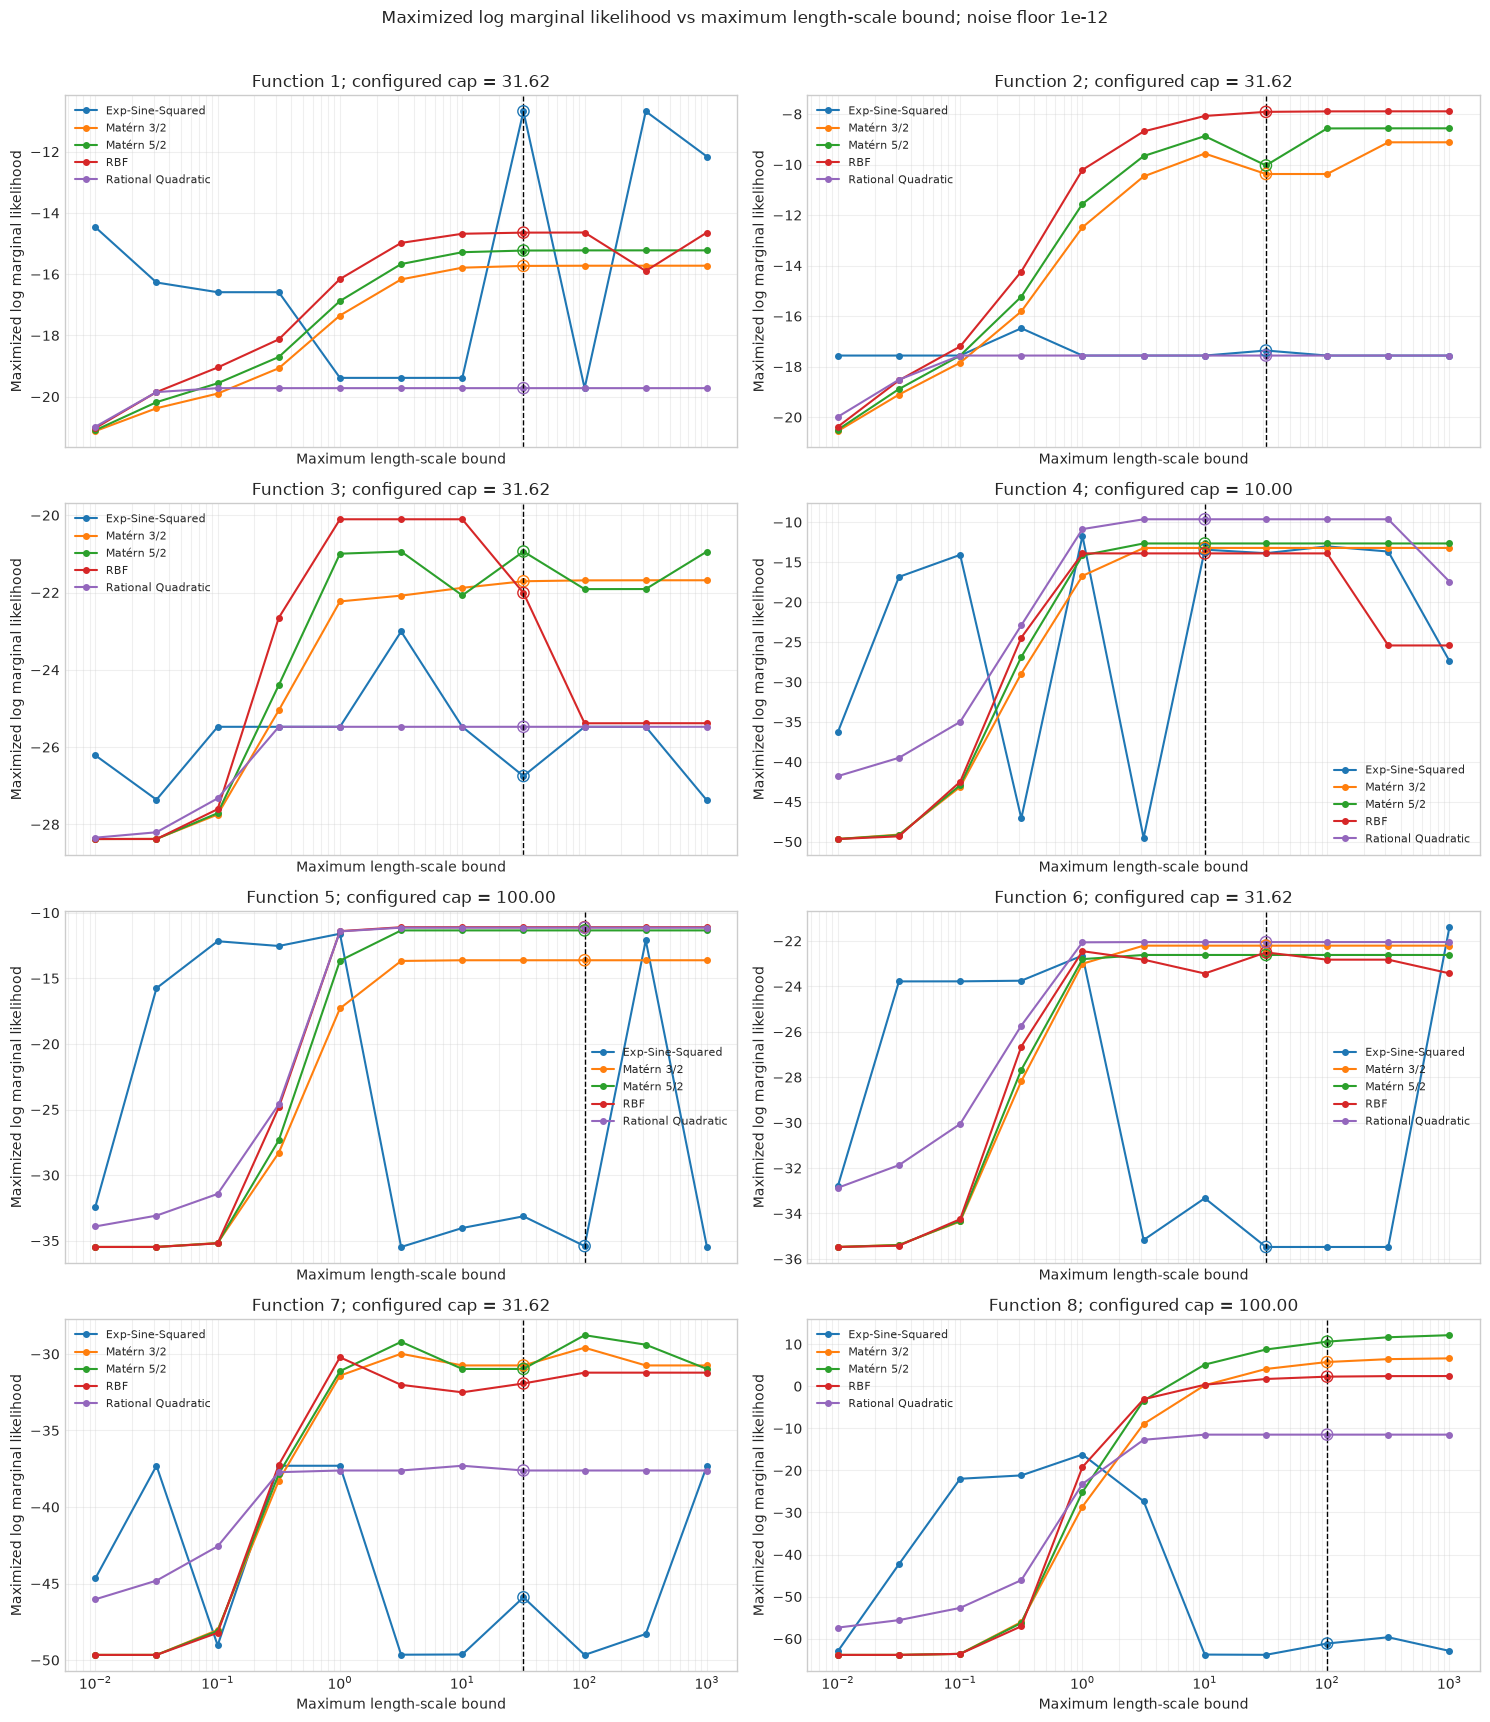

In [3]:
figure, axes = plt.subplots(4, 2, figsize=(15, 17), sharex=True, sharey=False)
for function_id, ax in zip(FUNCTION_IDS, axes.ravel()):
    rows = length_sensitivity.loc[length_sensitivity.function_id == function_id]
    current_cap = CONFIGURED_CAPS[function_id]
    for kernel_name, kernel_rows in rows.groupby('kernel', sort=False):
        line, = ax.plot(
            kernel_rows.max_length_scale, kernel_rows.max_log_marginal_likelihood,
            marker='o', markersize=4, label=kernel_name,
        )
        current = kernel_rows.loc[np.isclose(kernel_rows.max_length_scale, current_cap)]
        ax.scatter(
            current.max_length_scale, current.max_log_marginal_likelihood,
            s=65, facecolors='none', edgecolors=line.get_color(), zorder=5,
        )
    ax.axvline(current_cap, color='black', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_title(f'Function {function_id}; configured cap = {current_cap:.2f}')
    ax.set_xlabel('Maximum length-scale bound')
    ax.set_ylabel('Maximized log marginal likelihood')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=8)
figure.suptitle(
    f'Maximized log marginal likelihood vs maximum length-scale bound; noise floor {SWEEP_NOISE_FLOOR:g}',
    y=1.01,
)
figure.tight_layout()
plt.show()

## Compare the configured cap with the largest tested cap

- A plateau suggests that allowing larger scales adds little to the fitted likelihood. A rise suggests the cap constrains the fit, but does **not** establish better predictions or better EI decisions.
- With exact optimization, relaxing only an upper bound cannot lower the maximum likelihood. Dips here indicate numerical/local-optimizer sensitivity, despite the fixed seed and restarts.
- Compare likelihoods **within a function**, not across functions. Large ARD length scales indicate nearly flat fitted directions, not proven objective independence. Rational Quadratic uses one isotropic scale.
- Warnings can concern length scale, amplitude, noise, periodicity, or Rational Quadratic alpha. The table below labels each warning instead of assuming it concerns the cap. Kernel alpha is not EI alpha.

Use held-out accuracy and uncertainty calibration before changing the shared caps. The complete per-cap results remain in `length_sensitivity`, and all warning messages remain in `fit_warning_details`.

In [4]:
configured_rows = length_sensitivity.loc[np.isclose(
    length_sensitivity.max_length_scale,
    length_sensitivity.function_id.map(CONFIGURED_CAPS),
)]
largest_rows = length_sensitivity.groupby(['function_id', 'kernel'], sort=False).tail(1)
cap_comparison = configured_rows[[
    'function_id', 'kernel', 'max_length_scale', 'max_log_marginal_likelihood',
]].merge(largest_rows[[
    'function_id', 'kernel', 'max_length_scale', 'max_log_marginal_likelihood',
    'fitted_length_scales', 'convergence_warnings',
]], on=['function_id', 'kernel'], suffixes=('_configured', '_largest'), validate='one_to_one')
cap_comparison['lml_gain'] = (
    cap_comparison.max_log_marginal_likelihood_largest
    - cap_comparison.max_log_marginal_likelihood_configured
)
display(cap_comparison)
print('Warnings at the configured length caps, for all three noise floors:')
configured_warnings = fit_warning_details.loc[np.isclose(
    fit_warning_details.max_length_scale.to_numpy(dtype=float),
    fit_warning_details.function_id.map(CONFIGURED_CAPS).to_numpy(dtype=float),
)]
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(configured_warnings)

,function_id,kernel,max_length_scale_configured,max_log_marginal_likelihood_configured,max_length_scale_largest,max_log_marginal_likelihood_largest,fitted_length_scales,convergence_warnings,lml_gain
0,1,Exp-Sine-Squared,31.622777,-10.681878,1000.0,-12.159306,"(0.0360867078323899,)",0,-1.477428e+00
1,1,Matérn 3/2,31.622777,-15.730579,1000.0,-15.723802,"(0.027803278367134858, 999.9999999999998)",1,6.776853e-03
2,1,Matérn 5/2,31.622777,-15.228868,1000.0,-15.222605,"(0.025779825626305423, 999.9999999999998)",1,6.262648e-03
3,1,RBF,31.622777,-14.643495,1000.0,-14.639298,"(0.02094491808911792, 999.9999999999998)",1,4.196257e-03
4,1,Rational Quadratic,31.622777,-19.722482,1000.0,-19.722482,"(0.037767117364414834,)",2,1.123936e-10
5,2,Exp-Sine-Squared,31.622777,-17.362669,1000.0,-17.561626,"(0.004146646017344824,)",2,-1.989567e-01
6,2,Matérn 3/2,31.622777,-10.374299,1000.0,-9.118429,"(0.08372266996894867, 999.9999999999998)",1,1.255870e+00
7,2,Matérn 5/2,31.622777,-10.035138,1000.0,-8.565404,"(0.0733773464392425, 999.9999999999998)",1,1.469734e+00
8,2,RBF,31.622777,-7.913757,1000.0,-7.892597,"(0.05381015604163006, 999.9999999999998)",1,2.115988e-02
9,2,Rational Quadratic,31.622777,-17.561628,1000.0,-17.561626,"(0.0659966647587936,)",1,1.981702e-06


Warnings at the configured length caps, for all three noise floors:


,function_id,kernel,max_length_scale,noise_floor,category,message
48,1,Matérn 3/2,31.622777,1.000000e-12,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
49,1,Matérn 5/2,31.622777,1.000000e-12,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
50,1,RBF,31.622777,1.000000e-12,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
51,1,Rational Quadratic,31.622777,1.000000e-12,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
52,1,Rational Quadratic,31.622777,1.000000e-12,ConvergenceWarning,The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-12. Decreasing the bound and calling fit again may find a better value.
53,1,Exp-Sine-Squared,31.622777,1.000000e-12,ConvergenceWarning,lbfgs failed to converge after 13 iteration(s) (status=2):\nABNORMAL: \n\nYou might also want to scale the data as shown in:\n https://scikit-learn.org/stable/modules/preprocessing.html
67,1,Matérn 3/2,31.622777,1.000000e-08,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
68,1,Matérn 5/2,31.622777,1.000000e-08,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
69,1,RBF,31.622777,1.000000e-08,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
70,1,Rational Quadratic,31.622777,1.000000e-08,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.


## What changes when the noise floor decreases?

Hold the length cap at each function's configured value to isolate the noise-bound change. The table compares all five kernels at `1e-8`, `1e-10`, and `1e-12`; LML gain is relative to that same function/kernel at `1e-8`.

`fitted_noise` is a **variance**, in normalized-target units when `normalize_y=True`, not an output standard deviation. Lowering its bound permits a more nearly interpolating fit; it does not force the fitted noise down. The regressor's separate diagonal regularizer is unchanged. Check whether the optimum follows the new floor, remains above it, or switches to another local optimum. A lower noise estimate or fewer bound warnings does not establish better uncertainty calibration.

Relaxing the bound cannot reduce the theoretical maximum likelihood, but finite optimization can find a worse solution: changing bounds also changes the log-uniform random restart locations even with the same seed. Negative LML gains therefore flag optimizer sensitivity, not evidence that the extra flexibility is intrinsically worse.

In [5]:
noise_comparison = experiment_results.loc[np.isclose(
    experiment_results.max_length_scale,
    experiment_results.function_id.map(CONFIGURED_CAPS),
)].copy()
baseline = noise_comparison.loc[noise_comparison.noise_floor == NOISE_FLOORS[0], [
    'function_id', 'kernel', 'max_log_marginal_likelihood',
]].rename(columns={'max_log_marginal_likelihood': 'baseline_lml'})
noise_comparison = noise_comparison.merge(
    baseline, on=['function_id', 'kernel'], validate='many_to_one',
)
noise_comparison['lml_gain'] = noise_comparison.max_log_marginal_likelihood - noise_comparison.baseline_lml
noise_summary = noise_comparison.pivot(
    index=['function_id', 'kernel'], columns='noise_floor',
    values=['fitted_noise', 'lml_gain', 'noise_at_lower_bound'],
).reindex(columns=NOISE_FLOORS, level='noise_floor')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(noise_summary)
print('Full fit results: experiment_results; individual warnings: fit_warning_details.')

fitted_noise                            \
noise_floor                    1.000000e-08 1.000000e-10 1.000000e-12   
function_id kernel                                                      
1           Exp-Sine-Squared            0.0          0.0          0.0   
            Matérn 3/2             0.000656     0.000656     0.000656   
            Matérn 5/2             0.000651     0.000651     0.000651   
            RBF                    0.000646     0.000646     0.000646   
            Rational Quadratic          0.0          0.0          0.0   
2           Exp-Sine-Squared       0.000004          0.0          0.0   
            Matérn 3/2             0.004491     0.004491          0.0   
            Matérn 5/2             0.004737     0.004737     0.000001   
            RBF                    0.004401     0.004401     0.004401   
            Rational Quadratic          0.0          0.0          0.0   
3           Exp-Sine-Squared            0.0     0.000001          0.0   
            Matérn 3/2             0.000001          0.0          0.0   
            Matérn 5/2             0.000005          0.0          0.0   
            RBF                    0.000005          0.0          0.0   
            Rational Quadratic          0.0          0.0          0.0   
4           Exp-Sine-Squared       0.753338      0.29045     0.004318   
            Matérn 3/2             0.001622     0.001622     0.001622   
            Matérn 5/2             0.003162     0.003162     0.003162   
            RBF                    0.003817     0.003817     0.003817   
            Rational Quadratic     0.003561     0.003561     0.003561   
5           Exp-Sine-Squared       0.989037      0.00001      0.85673   
            Matérn 3/2                  0.0          0.0          0.0   
            Matérn 5/2             0.000586     0.000586     0.000586   
            RBF                    0.001127     0.001127     0.001127   
            Rational Quadratic     0.000613     0.000613     0.000613   
6           Exp-Sine-Squared       0.986042     0.000001     0.746316   
            Matérn 3/2             0.003802      0.00001      0.00001   
            Matérn 5/2              0.00001      0.00001      0.00001   
            RBF                    0.025027     0.025018          0.0   
            Rational Quadratic     0.000004          0.0          0.0   
7           Exp-Sine-Squared            0.0     0.000001          0.0   
            Matérn 3/2             0.048314     0.048314      0.00001   
            Matérn 5/2              0.00002     0.049678      0.00001   
            RBF                    0.052919      0.05211          0.0   
            Rational Quadratic      0.00001     0.072206      0.00001   
8           Exp-Sine-Squared       0.989366     0.985888          0.0   
            Matérn 3/2                  0.0          0.0          0.0   
            Matérn 5/2                  0.0          0.0          0.0   
            RBF                         0.0          0.0          0.0   
            Rational Quadratic          0.0          0.0          0.0   

                                   lml_gain                            \
noise_floor                    1.000000e-08 1.000000e-10 1.000000e-12   
function_id kernel                                                      
1           Exp-Sine-Squared            0.0     0.875072     2.587034   
            Matérn 3/2                  0.0          0.0          0.0   
            Matérn 5/2                  0.0          0.0         -0.0   
            RBF                         0.0         -0.0         -0.0   
            Rational Quadratic          0.0         -0.0          0.0   
2           Exp-Sine-Squared            0.0    -0.880473    -0.874625   
            Matérn 3/2                  0.0         -0.0    -1.185054   
            Matérn 5/2                  0.0         -0.0    -1.427972   
            RBF                         0.0          0.0         -0.0   
            Rat

Full fit results: experiment_results; individual warnings: fit_warning_details.


### Findings from this saved run

At the configured length caps, for the kernels currently selected in [notebook 06](06_gaussian_estimations.ipynb):

- **F1 (Rational Quadratic):** fitted noise follows the floor from `1e-8` to `1e-12`, but LML improves by only about `1.2e-7`.
- **F8 (Rational Quadratic):** fitted noise moves from `1e-8` to about `3.8e-11`; LML improves by only about `1.1e-5`. It no longer reaches the `1e-12` floor.
- **F3 and F6 (Rational Quadratic):** noise estimates drop substantially, while LML improves by only about `1.4e-6` and `1.6e-4`, respectively. The noise estimate is weakly determined by these fits.
- **F2 (RBF), F4 (Matérn 3/2), and F5 (Rational Quadratic):** fitted noise and likelihood are essentially unchanged.
- **F7 (Matérn 3/2):** the `1e-12` run finds a worse local solution: LML falls by about `1.51`, and fitted noise moves from `0.0483` to about `1e-5`. This is optimizer sensitivity, not a benefit from lowering the noise floor; the baseline fit remains a feasible alternative.

Across all 40 function/kernel pairs, the number fitted at the noise floor falls from **8** (`1e-8`) to **6** (`1e-10`) to **3** (`1e-12`). Fewer boundary hits do not imply better predictive calibration. These results do not justify changing shared noise defaults on their own.